# 09 — Hyperparameter Tuning and Experiment Tracking

**A practical PyTorch lesson on designing experiments, searching hyperparameters, comparing runs, and selecting a model without leaking test information.**

A model's performance depends on its architecture and on choices made before and during training. We will create a synthetic classification task, build a reusable training pipeline, compare controlled experiments, run a small random search, visualize results, and evaluate the selected configuration on a held-out test set.

The dataset is synthetic and is used for teaching only; the results are not evidence of real-world or clinical performance.

## 1. Learning objectives

By the end, you should be able to:
- Distinguish learned parameters from hyperparameters.
- Explain learning rate, batch size, weight decay, dropout, and hidden-layer width.
- Design fair experiments and compare configurations.
- Implement a reusable PyTorch training and validation loop.
- Run random search and log results in a table.
- Visualize the relationship between hyperparameters and validation performance.
- Explain why the test set must not be used to choose hyperparameters.

**Prerequisites:** the earlier notebooks on PyTorch, training and optimization, and model evaluation.

## 2. Parameters vs. hyperparameters

**Model parameters** are learned from training data, such as the weights and biases in `nn.Linear`.

**Hyperparameters** are choices we set, such as learning rate, batch size, hidden-layer width, dropout probability, and weight decay.

A simplified training objective is:

$$
\theta^*(\lambda) = \arg\min_{\theta} L_{\mathrm{train}}(\theta;\lambda)
$$

Here, $\theta$ represents learned parameters and $\lambda$ represents a hyperparameter configuration. We choose $\lambda$ by comparing validation performance, not by repeatedly optimizing against the test set.

## 3. Imports and reproducibility

A fixed seed makes the experiment easier to reproduce, but exact results may still differ across hardware, library versions, and nondeterministic operations.

In [1]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import sklearn

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("Device:", device)

PyTorch: 2.5.1+cu121
scikit-learn: 1.9.0
Device: cuda


## 4. Create the dataset and split it correctly

- **Training set:** learns model weights.
- **Validation set:** compares configurations and selects the final configuration.
- **Test set:** estimates final performance after development decisions are complete.

We will not use test labels to select hyperparameters.

In [3]:
X, y = make_classification(
    n_samples=3000, n_features=12, n_informative=7, n_redundant=3,
    n_classes=2, weights=[0.70, 0.30], class_sep=1.0,
    flip_y=0.025, random_state=SEED
)

# Hold out the final test set first.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
# Split the development data into training and validation sets.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED
)

display(pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Positive fraction": [y_train.mean(), y_val.mean(), y_test.mean()],
}).round(3))

,Split,Samples,Positive fraction
0,Train,1800,0.304
1,Validation,600,0.303
2,Test,600,0.303


### 4.1 Standardize without data leakage

For standardization,

$$
x_{\mathrm{scaled}} = \frac{x - \mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

Fit the scaler on training features only. Apply the same learned transformation to validation and test features. Fitting preprocessing on all data can leak information from held-out samples.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Learn from train only.
X_val_scaled = scaler.transform(X_val)          # Reuse train statistics.
X_test_scaled = scaler.transform(X_test)

print("Train means (first 4):", np.round(X_train_scaled.mean(axis=0)[:4], 3))
print("Validation means (first 4):", np.round(X_val_scaled.mean(axis=0)[:4], 3))

Train means (first 4): [-0. -0. -0. -0.]
Validation means (first 4): [ 0.006  0.061  0.043 -0.037]


## 5. Hyperparameters in this notebook

| Hyperparameter | What it controls | Common trade-off |
|---|---|---|
| Learning rate | Size of optimizer updates | Too high can destabilize training; too low can slow it |
| Batch size | Samples per gradient update | Affects memory, update frequency, and gradient noise |
| Hidden units | Width of hidden layers | More capacity can fit complex patterns but may overfit |
| Dropout | Fraction of activations zeroed during training | Too much can underfit |
| Weight decay | Regularization of parameter magnitudes | Too much can restrict learning |

These are starting intuitions, not universal rules. Effects depend on the data, model, optimizer, and training duration.

In [5]:
class ConfigurableMLP(nn.Module):
    """MLP for binary classification; returns raw logits."""
    def __init__(self, input_features, hidden_units=32, dropout=0.1):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_units, hidden_units // 2),
            nn.ReLU(),
            nn.Linear(hidden_units // 2, 1),
        )

    def forward(self, x):
        return self.layers(x)  # BCEWithLogitsLoss expects logits.

print(ConfigurableMLP(X_train_scaled.shape[1]))

ConfigurableMLP(
  (layers): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 6. Reusable training and validation functions

We use `BCEWithLogitsLoss`, which combines sigmoid and binary cross-entropy in a numerically stable loss. The model therefore returns logits rather than probabilities.

The learning rate controls optimizer step size. Weight decay and dropout are regularization choices that may improve generalization, but can also be too strong.

In [6]:
def set_seed(seed=SEED):
    """Reset random generators before each independent trial."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_loader(X_array, y_array, batch_size, shuffle):
    """Convert NumPy arrays to a DataLoader with consistent tensor types."""
    features = torch.tensor(X_array, dtype=torch.float32)
    labels = torch.tensor(y_array, dtype=torch.float32).view(-1, 1)
    dataset = TensorDataset(features, labels)
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)


def evaluate_loss(model, loader, loss_fn):
    """Return average loss without tracking gradients."""
    model.eval()
    total_loss, total_count = 0.0, 0
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            loss = loss_fn(model(features), labels)
            total_loss += loss.item() * len(features)
            total_count += len(features)
    return total_loss / total_count


def train_configuration(config, max_epochs=15, seed=SEED):
    """Train one configuration; return metrics, history, and best weights."""
    set_seed(seed)
    train_loader = make_loader(X_train_scaled, y_train, config["batch_size"], True)
    val_loader = make_loader(X_val_scaled, y_val, config["batch_size"], False)

    model = ConfigurableMLP(
        X_train_scaled.shape[1], config["hidden_units"], config["dropout"]
    ).to(device)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )

    history = {"train_loss": [], "val_loss": []}
    best_loss, best_state = float("inf"), None

    for epoch in range(max_epochs):
        model.train()
        running_loss, count = 0.0, 0

        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(features), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(features)
            count += len(features)

        train_loss = running_loss / count
        val_loss = evaluate_loss(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.to(device)
    model.eval()
    with torch.no_grad():
        x_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
        val_prob = torch.sigmoid(model(x_val_tensor).squeeze(1)).cpu().numpy()

    val_pred = (val_prob >= 0.5).astype(int)
    metrics = {
        "best_val_loss": best_loss,
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_f1": f1_score(y_val, val_pred, zero_division=0),
        "val_roc_auc": roc_auc_score(y_val, val_prob),
    }
    return metrics, history, best_state

## 7. Establish a baseline

Start with one documented configuration. The baseline gives us a reference point before running a larger search.

Baseline configuration:


,Value
learning_rate,0.0010
weight_decay,0.0001
hidden_units,32.0000
dropout,0.1000
batch_size,64.0000


,Baseline
best_val_loss,0.2752
val_accuracy,0.8950
val_f1,0.8215
val_roc_auc,0.9427


Training time: 4.22 seconds


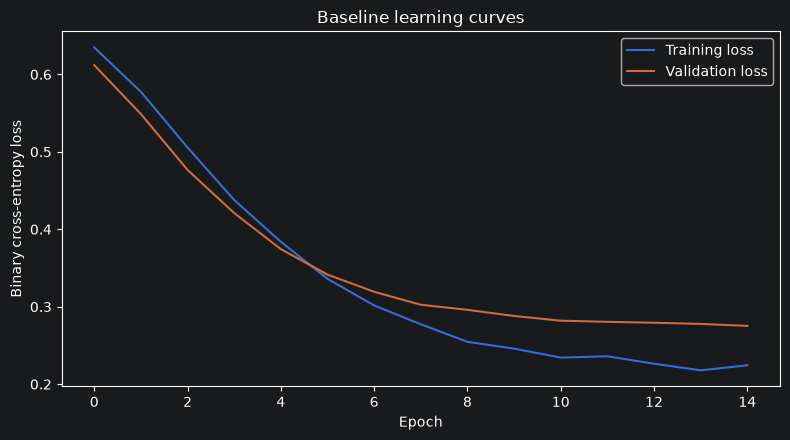

In [7]:
baseline_config = {
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "hidden_units": 32,
    "dropout": 0.10,
    "batch_size": 64,
}

start = time.perf_counter()
baseline_metrics, baseline_history, baseline_state = train_configuration(baseline_config)
baseline_seconds = time.perf_counter() - start

print("Baseline configuration:")
display(pd.Series(baseline_config, name="Value").to_frame())
display(pd.Series(baseline_metrics, name="Baseline").to_frame().round(4))
print(f"Training time: {baseline_seconds:.2f} seconds")

plt.figure(figsize=(8, 4.5))
plt.plot(baseline_history["train_loss"], label="Training loss")
plt.plot(baseline_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Baseline learning curves")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Controlled experiment: compare learning rates

A controlled comparison changes one setting while keeping the others fixed. This makes the results easier to interpret than changing many values at once.

,learning_rate,best_val_loss,val_accuracy,val_f1,val_roc_auc,seconds
0,0.0001,0.5677,0.7183,0.1421,0.7737,1.4275
1,0.0003,0.3795,0.8167,0.6284,0.9086,1.2690
2,0.0010,0.2752,0.8950,0.8215,0.9427,1.2555
3,0.0030,0.2579,0.9100,0.8508,0.9495,1.2664


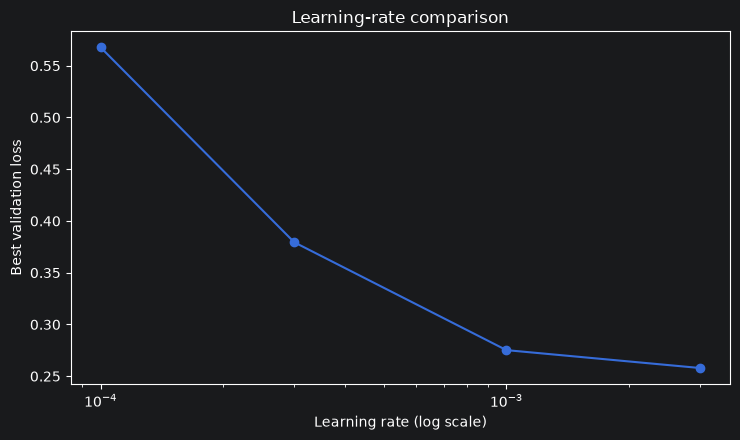

In [9]:
learning_rates = [1e-4, 3e-4, 1e-3, 3e-3]
lr_records = []

for lr in learning_rates:
    config = {**baseline_config, "learning_rate": lr}
    start = time.perf_counter()
    metrics, _, _ = train_configuration(config)
    lr_records.append({
        "learning_rate": lr,
        **metrics,
        "seconds": time.perf_counter() - start,
    })

lr_results = pd.DataFrame(lr_records)
display(lr_results.round(4))

plt.figure(figsize=(7.5, 4.5))
plt.plot(lr_results["learning_rate"], lr_results["best_val_loss"], marker="o")
plt.xscale("log")
plt.xlabel("Learning rate (log scale)")
plt.ylabel("Best validation loss")
plt.title("Learning-rate comparison")
plt.tight_layout()
plt.show()

## 9. Random search

Grid search tests every combination in a predefined grid. Random search samples combinations from chosen ranges and categories. It is a practical baseline when only a few hyperparameters may strongly affect performance.

This search is intentionally small so the notebook remains practical on a CPU. It is not an exhaustive optimization study.

In [10]:
search_space = {
    "learning_rate": (1e-4, 3e-3),  # Sample on a log scale.
    "weight_decay": (1e-6, 1e-2),   # Sample on a log scale.
    "hidden_units": [16, 32, 64],
    "dropout": [0.0, 0.1, 0.2, 0.35],
    "batch_size": [32, 64, 128],
}

def sample_configuration(rng):
    """Sample one hyperparameter configuration."""
    return {
        "learning_rate": 10 ** rng.uniform(
            np.log10(search_space["learning_rate"][0]),
            np.log10(search_space["learning_rate"][1]),
        ),
        "weight_decay": 10 ** rng.uniform(
            np.log10(search_space["weight_decay"][0]),
            np.log10(search_space["weight_decay"][1]),
        ),
        "hidden_units": rng.choice(search_space["hidden_units"]),
        "dropout": rng.choice(search_space["dropout"]),
        "batch_size": rng.choice(search_space["batch_size"]),
    }

rng = random.Random(SEED)
n_trials = 8
sampled_configs = [sample_configuration(rng) for _ in range(n_trials)]
display(pd.DataFrame(sampled_configs).round(6))

,learning_rate,weight_decay,hidden_units,dropout,batch_size
0,0.000880,0.000001,32,0.10,32
1,0.000161,0.000003,64,0.00,128
2,0.000420,0.000001,16,0.10,128
3,0.000775,0.000176,64,0.35,32
4,0.000461,0.000013,16,0.10,128
5,0.000421,0.000013,16,0.20,32
6,0.000137,0.000002,32,0.20,32
7,0.001196,0.000140,32,0.00,128


### 9.1 Run trials and track results

For each trial, we record its configuration, validation metrics, duration, and trial number. We select the best configuration by **lowest validation loss**, a criterion chosen before looking at the test results.

In [11]:
trial_records = []
trial_states = []
trial_histories = []

for trial_number, config in enumerate(sampled_configs, start=1):
    start = time.perf_counter()
    metrics, history, state = train_configuration(config, max_epochs=15)
    elapsed = time.perf_counter() - start

    trial_records.append({
        "trial": trial_number,
        **config,
        **metrics,
        "seconds": elapsed,
    })
    trial_states.append(state)
    trial_histories.append(history)

    print(
        f"Trial {trial_number:02d}/{n_trials} | "
        f"val_loss={metrics['best_val_loss']:.4f} | "
        f"val_f1={metrics['val_f1']:.3f} | time={elapsed:.1f}s"
    )

results = pd.DataFrame(trial_records).sort_values(
    "best_val_loss", ascending=True
).reset_index(drop=True)
display(results.round(4))

Trial 01/8 | val_loss=0.2719 | val_f1=0.824 | time=2.4s
Trial 02/8 | val_loss=0.5023 | val_f1=0.533 | time=0.8s
Trial 03/8 | val_loss=0.5309 | val_f1=0.567 | time=0.8s
Trial 04/8 | val_loss=0.2627 | val_f1=0.837 | time=2.3s
Trial 05/8 | val_loss=0.5143 | val_f1=0.570 | time=0.8s
Trial 06/8 | val_loss=0.3148 | val_f1=0.780 | time=2.3s
Trial 07/8 | val_loss=0.4339 | val_f1=0.568 | time=2.3s
Trial 08/8 | val_loss=0.2868 | val_f1=0.789 | time=0.8s


,trial,learning_rate,weight_decay,hidden_units,dropout,batch_size,best_val_loss,val_accuracy,val_f1,val_roc_auc,seconds
0,4,0.0008,0.0002,64,0.35,32,0.2627,0.9033,0.8371,0.9485,2.2705
1,1,0.0009,0.0000,32,0.10,32,0.2719,0.8950,0.8235,0.9444,2.4419
2,8,0.0012,0.0001,32,0.00,128,0.2868,0.8800,0.7895,0.9385,0.7731
3,6,0.0004,0.0000,16,0.20,32,0.3148,0.8733,0.7803,0.9295,2.3277
4,7,0.0001,0.0000,32,0.20,32,0.4339,0.8050,0.5683,0.8783,2.3078
5,2,0.0002,0.0000,64,0.00,128,0.5023,0.7983,0.5328,0.8456,0.8351
6,5,0.0005,0.0000,16,0.10,128,0.5143,0.8017,0.5704,0.8345,0.7993
7,3,0.0004,0.0000,16,0.10,128,0.5309,0.7967,0.5674,0.8262,0.8231


## 10. Visualize and interpret search results

With a small number of trials, plots are exploratory. Apparent patterns are not proof that a hyperparameter has a universal effect.

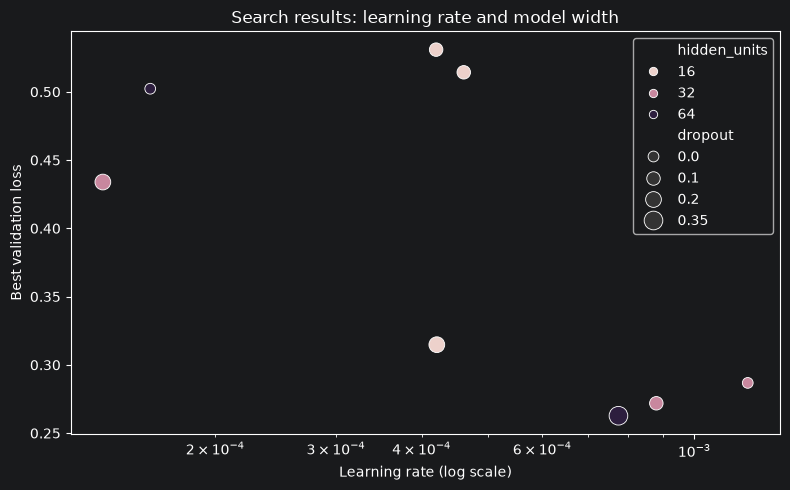

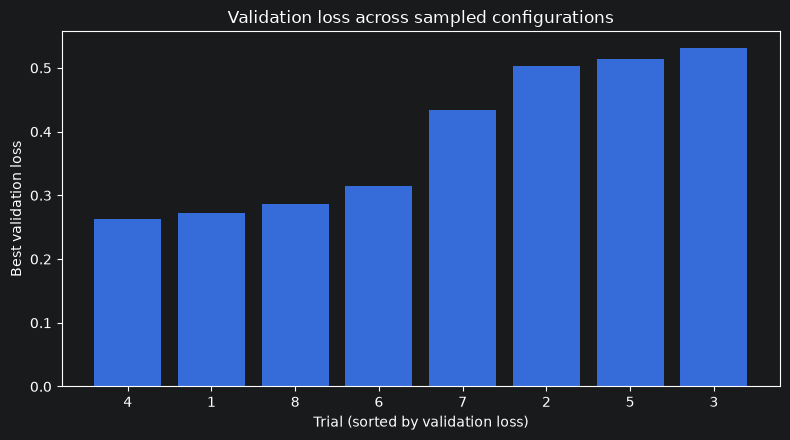

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=results, x="learning_rate", y="best_val_loss",
    hue="hidden_units", size="dropout", sizes=(60, 180)
)
plt.xscale("log")
plt.xlabel("Learning rate (log scale)")
plt.ylabel("Best validation loss")
plt.title("Search results: learning rate and model width")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(results["trial"].astype(str), results["best_val_loss"])
plt.xlabel("Trial (sorted by validation loss)")
plt.ylabel("Best validation loss")
plt.title("Validation loss across sampled configurations")
plt.tight_layout()
plt.show()

Questions to ask:
- Did the best configuration outperform the baseline by a meaningful amount?
- Did several configurations perform similarly?
- Did a configuration with good loss have a different F1 score?
- Was the improvement worth its compute cost?
- Could random variation explain some of the difference?

A small search suggests promising configurations; it does not prove global optimality.

## 11. Save the experiment log

Saving results makes experiments easier to compare and audit later. This writes a CSV file to the notebook's current working directory.

In [13]:
results_path = Path("09_hyperparameter_search_results.csv")
results.to_csv(results_path, index=False)
print(f"Saved experiment log to: {results_path.resolve()}")

Saved experiment log to: C:\Users\mobin\Downloads\09_hyperparameter_search_results.csv


## 12. Select a configuration using validation data

We select the configuration with the lowest validation loss. This is a development decision based on validation results; the test labels have not been used to choose it.

In [14]:
best_row = results.iloc[0]
best_config = {
    "learning_rate": float(best_row["learning_rate"]),
    "weight_decay": float(best_row["weight_decay"]),
    "hidden_units": int(best_row["hidden_units"]),
    "dropout": float(best_row["dropout"]),
    "batch_size": int(best_row["batch_size"]),
}
selected_trial = int(best_row["trial"])

print("Selected configuration:")
display(pd.Series(best_config, name="Value").to_frame())
print(f"Best validation loss: {best_row['best_val_loss']:.4f}")

Selected configuration:


,Value
learning_rate,0.000775
weight_decay,0.000176
hidden_units,64.000000
dropout,0.350000
batch_size,32.000000


Best validation loss: 0.2627


## 13. Final evaluation on the held-out test set

Now we evaluate the selected trial's saved weights on the test features. The test set was not used for fitting or hyperparameter selection.

For a larger study, you may choose to retrain the selected configuration on training plus validation data after freezing all decisions. If so, define that protocol in advance and preserve an untouched test set.

In [15]:
final_model = ConfigurableMLP(
    X_train_scaled.shape[1],
    best_config["hidden_units"],
    best_config["dropout"],
).to(device)

# Trials are stored in original trial order; the result table is sorted.
final_model.load_state_dict(trial_states[selected_trial - 1])
final_model.eval()

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
with torch.no_grad():
    test_logits = final_model(X_test_tensor).squeeze(1)
    test_probabilities = torch.sigmoid(test_logits).cpu().numpy()

test_predictions = (test_probabilities >= 0.5).astype(int)
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
}, name="Test result")

display(test_metrics.to_frame().round(4))

,Test result
Accuracy,0.9450
F1,0.9070
ROC-AUC,0.9835


**Important:** this test score estimates performance on this held-out split; it does not guarantee future performance. If you change the search space, model, threshold, or training protocol based on these test results, you have used the test set for development and should seek a new independent final evaluation.

## 14. Optional extension: automated tuning with Optuna

The manual random search helps explain the mechanics. For larger searches, tools can automate sampling, pruning unpromising trials, and experiment management.

Optuna is one option. To try it in Jupyter, install it in a separate step:

```python
%pip install optuna
```

An Optuna objective typically:
1. asks a trial to suggest hyperparameter values;
2. trains a model using those values;
3. returns a validation metric;
4. lets the study's sampler choose subsequent trials.

The following is an optional example; the rest of this notebook does not require Optuna.

In [16]:
# Optional: run only after installing Optuna.
# import optuna
#
# def objective(trial):
#     config = {
#         "learning_rate": trial.suggest_float("learning_rate", 1e-4, 3e-3, log=True),
#         "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
#         "hidden_units": trial.suggest_categorical("hidden_units", [16, 32, 64]),
#         "dropout": trial.suggest_categorical("dropout", [0.0, 0.1, 0.2, 0.35]),
#         "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128]),
#     }
#     metrics, _, _ = train_configuration(config, max_epochs=15)
#     return metrics["best_val_loss"]
#
# study = optuna.create_study(direction="minimize")
# study.optimize(objective, n_trials=8)
# print("Best value:", study.best_value)
# print("Best parameters:", study.best_params)

## 15. Common mistakes

- Choosing configurations based on test-set results.
- Changing many hyperparameters at once and drawing unsupported conclusions.
- Comparing runs on different splits.
- Fitting preprocessing on validation or test data.
- Forgetting to create a fresh model for each trial.
- Comparing runs with different training budgets without noting it.
- Recording only the best result and discarding other trials.
- Treating the best of a small random search as a proven global optimum.
- Optimizing a metric that does not match the real task.
- Ignoring compute cost, variability, or model complexity.

## 16. Practical exercises

1. Expand the learning-rate comparison and explain how the learning curves change.
2. Compare batch sizes `16`, `32`, `64`, and `128`; record validation loss and runtime.
3. Compare weight decay and dropout while keeping other settings fixed.
4. Run 5, 10, and 20 random trials. Does the best validation loss improve consistently?
5. Repeat the top two configurations with three random seeds and report mean and standard deviation.
6. Write a short experiment report: search space, trial count, selection criterion, best validation result, final test metrics, and limitations.
7. Optionally install Optuna and compare it with manual random search under a similar trial budget.

## 17. Key takeaways

- Model parameters are learned; hyperparameters are selected by the experimenter.
- Validation data guide model selection.
- A baseline helps judge whether tuning is worthwhile.
- Controlled experiments improve interpretability.
- Random search is a practical starting point for mixed search spaces.
- Experiment logs support reproducibility and auditability.
- The selected configuration should be evaluated on an untouched test set only after development choices are complete.
- More trials do not automatically make a study better; relevant metrics, appropriate splits, and honest reporting matter.

## 18. Quick reference

| Task | Practical approach |
|---|---|
| Set random seeds | Seed Python, NumPy, and PyTorch |
| Establish a reference | Train and document a baseline |
| Search learning rate | Use a log-scale range across orders of magnitude |
| Compare configurations | Keep data splits and metrics consistent |
| Select a model | Use validation metrics |
| Final evaluation | Use the held-out test set after choices are frozen |
| Record results | Save configuration, metrics, duration, and trial ID |
| Scale up tuning | Consider Optuna or Ray Tune |

## 19. Official documentation

1. **PyTorch — Hyperparameter Tuning with Ray Tune**  
   https://docs.pytorch.org/tutorials/beginner/hyperparameter_tuning_tutorial.html

2. **PyTorch — `torch.optim`**  
   https://docs.pytorch.org/docs/stable/optim.html

3. **PyTorch — Optimization Tutorial**  
   https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html

4. **Optuna — Official Documentation**  
   https://optuna.readthedocs.io/en/stable/

5. **scikit-learn — Common Pitfalls and Recommended Practices**  
   https://scikit-learn.org/stable/common_pitfalls.html

**Scope note:** this is a self-contained teaching example. Adapt the split strategy, metric, search space, compute budget, and validation protocol to the actual problem.